# EX5 EDA on Airlines Delay Data

#### We will conduct basic EDA on airlines delays datasets.

- Conduct basic preprocessing

- Apply EDA on chosen data


#### Airlines delay datasets

- Flight delay explanatory data analysis using airlines delay datasets

https://www.kaggle.com/giovamata/airlinedelaycauses

- EDA examples:

https://www.kaggle.com/adveros/flight-delay-eda-exploratory-data-analysis

- a complete report of airlines delay can be found in Canvas Week 4. 

### Part 0:
    
- Examples below are the EDA for airlines delays 2020 data

- Run through the code and check preprocessing and some tools of EDA. 

In [38]:
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [39]:
data = pd.read_csv('./data/airtrans_2020_Jan.csv') 
# if there are any missing values, then fill in with NaN
data = data.fillna(np.nan)
data.head()

,flight_date,unique_carrier,flight_num,origin,dest,dep_delay,arr_delay,cancelled,actual_elapsed_time,distance,carrier_delay,weather_delay,late_aircraft_dealy
0,1/1/20,WN,5888,ONT,SFO,41.0,68.0,0,122.0,363,8.0,0.0,33.0
1,1/1/20,WN,6276,ONT,SFO,-4.0,-2.0,0,92.0,363,NaN,NaN,NaN
2,1/1/20,WN,4598,ONT,SJC,-4.0,-6.0,0,68.0,333,NaN,NaN,NaN
3,1/1/20,WN,4761,ONT,SJC,10.0,10.0,0,75.0,333,NaN,NaN,NaN
4,1/1/20,WN,5162,ONT,SJC,1.0,-12.0,0,67.0,333,NaN,NaN,NaN


#### Python lambda

- see the examples of lambda

https://www.w3schools.com/python/python_lambda.asp

In [40]:
# add a new column with 'delayed' as key with values either True or False
data['delayed'] = data['arr_delay'].apply(lambda x: x > 0) 

data.head()

,flight_date,unique_carrier,flight_num,origin,dest,dep_delay,arr_delay,cancelled,actual_elapsed_time,distance,carrier_delay,weather_delay,late_aircraft_dealy,delayed
0,1/1/20,WN,5888,ONT,SFO,41.0,68.0,0,122.0,363,8.0,0.0,33.0,True
1,1/1/20,WN,6276,ONT,SFO,-4.0,-2.0,0,92.0,363,NaN,NaN,NaN,False
2,1/1/20,WN,4598,ONT,SJC,-4.0,-6.0,0,68.0,333,NaN,NaN,NaN,False
3,1/1/20,WN,4761,ONT,SJC,10.0,10.0,0,75.0,333,NaN,NaN,NaN,True
4,1/1/20,WN,5162,ONT,SJC,1.0,-12.0,0,67.0,333,NaN,NaN,NaN,False


In [41]:
# create a new DataFrame containing only delayed flights
delayed_flights = data[data['delayed'] == True]

delayed_flights.head()

,flight_date,unique_carrier,flight_num,origin,dest,dep_delay,arr_delay,cancelled,actual_elapsed_time,distance,carrier_delay,weather_delay,late_aircraft_dealy,delayed
0,1/1/20,WN,5888,ONT,SFO,41.0,68.0,0,122.0,363,8.0,0.0,33.0,True
3,1/1/20,WN,4761,ONT,SJC,10.0,10.0,0,75.0,333,NaN,NaN,NaN,True
5,1/1/20,WN,5684,ONT,SJC,2.0,7.0,0,80.0,333,NaN,NaN,NaN,True
7,1/1/20,WN,1679,ONT,SMF,59.0,47.0,0,73.0,390,0.0,0.0,40.0,True
8,1/1/20,WN,3479,ONT,SMF,-5.0,10.0,0,100.0,390,NaN,NaN,NaN,True


In [42]:
# how many unique carriers that have delayed flights
delayed_flights['unique_carrier'].value_counts()

unique_carrier
WN    24134
AA    22706
DL    18692
OO    18242
UA    12133
OH     9433
MQ     8944
AS     8062
YX     6838
B6     6603
YV     5698
NK     4589
9E     4300
F9     3117
EV     2975
G4     2788
HA     2371
Name: count, dtype: int64

In [43]:
# retrieve flights with delayed information (False or True)
# group the data based on unique_carrier and count them.
delayed_by_carrier = data.groupby(['unique_carrier', 'delayed']).size().unstack()
delayed_by_carrier

delayed,False,True
unique_carrier,,
9E,18768,4300
AA,53570,22706
AS,13048,8062
B6,18106,6603
DL,61375,18692
EV,7589,2975
F9,9350,3117
G4,4986,2788
HA,4664,2371


In [44]:
# set default index (0, 1, 2, 3, ...)

delayed_by_carrier = delayed_by_carrier.reset_index()
delayed_by_carrier[:5]

delayed,unique_carrier,False,True
0,9E,18768,4300
1,AA,53570,22706
2,AS,13048,8062
3,B6,18106,6603
4,DL,61375,18692


In [45]:
# add a new column of the total flights
delayed_by_carrier['flight_count'] = delayed_by_carrier[False] + delayed_by_carrier[True]

# display top 5 rows
delayed_by_carrier[:5]

delayed,unique_carrier,False,True,flight_count
0,9E,18768,4300,23068
1,AA,53570,22706,76276
2,AS,13048,8062,21110
3,B6,18106,6603,24709
4,DL,61375,18692,80067


In [46]:
# calculate the ratio of delayed flights
delayed_by_carrier['proportion_delayed'] = delayed_by_carrier[True] / delayed_by_carrier['flight_count']

# display top 5 rows
delayed_by_carrier[:5]

delayed,unique_carrier,False,True,flight_count,proportion_delayed
0,9E,18768,4300,23068,0.186405
1,AA,53570,22706,76276,0.297682
2,AS,13048,8062,21110,0.381904
3,B6,18106,6603,24709,0.267231
4,DL,61375,18692,80067,0.233454


In [47]:
# sort the data
delayed_by_carrier.sort_values('proportion_delayed', ascending=False)

delayed,unique_carrier,False,True,flight_count,proportion_delayed
11,OH,14876,9433,24309,0.388046
2,AS,13048,8062,21110,0.381904
7,G4,4986,2788,7774,0.358631
9,MQ,17256,8944,26200,0.341374
8,HA,4664,2371,7035,0.337029
15,YV,12138,5698,17836,0.319466
1,AA,53570,22706,76276,0.297682
5,EV,7589,2975,10564,0.281617
3,B6,18106,6603,24709,0.267231
10,NK,12888,4589,17477,0.262574


### pivot_table()

- see examples of pivot_table()

https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.pivot_table.html

In [48]:
data.pivot_table(columns='unique_carrier', values='arr_delay')

unique_carrier,9E,AA,AS,B6,DL,EV,F9,G4,HA,MQ,NK,OH,OO,UA,WN,YV,YX
arr_delay,-6.155347,0.273081,1.594428,-3.00329,-4.418101,-0.436295,-4.48205,6.411197,-1.057733,3.953014,-1.570703,7.828951,1.265104,-2.796893,-5.587468,5.8516,-5.319191


In [49]:
# retrieve the information of arrival delay of South West 
southwest = data[data['unique_carrier'] == 'WN']['arr_delay']
southwest.head()

0    68.0
1    -2.0
2    -6.0
3    10.0
4   -12.0
Name: arr_delay, dtype: float64

In [50]:
southwest.describe()

count    107708.000000
mean         -5.587468
std          23.635321
min         -68.000000
25%         -17.000000
50%         -10.000000
75%          -1.000000
max         597.000000
Name: arr_delay, dtype: float64

count: there are 42,020 rows in the dataset, which is filtered to only show Southwest (WN).

mean: the average delay.
std: the standard deviation. More on this below.

min: the shortest delay in the dataset. In this case, the flight was very early.

25%: the 25th percentile. 25% of delays were lower than -9.00.

50%: the 50th percentile, or the median. 50% of delays were lower than 1.00.

75%: the 75th percentile. 75% of delays were lower than 19.00.

max: the longest delay in the dataset: 535.00.

In [51]:
wn_carrier = data[data['unique_carrier'] == 'WN']
wn_carrier['arr_delay'][:5]

0    68.0
1    -2.0
2    -6.0
3    10.0
4   -12.0
Name: arr_delay, dtype: float64

### Another way to plot box plots and histograms

<Axes: >

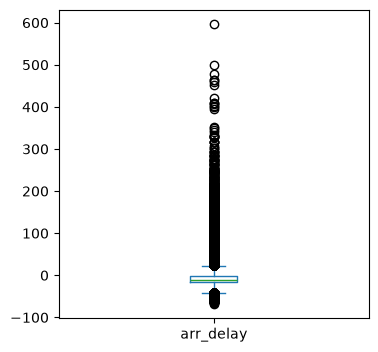

In [52]:
wn_carrier['arr_delay'].plot(kind='box', figsize=[4, 4])

<Axes: >

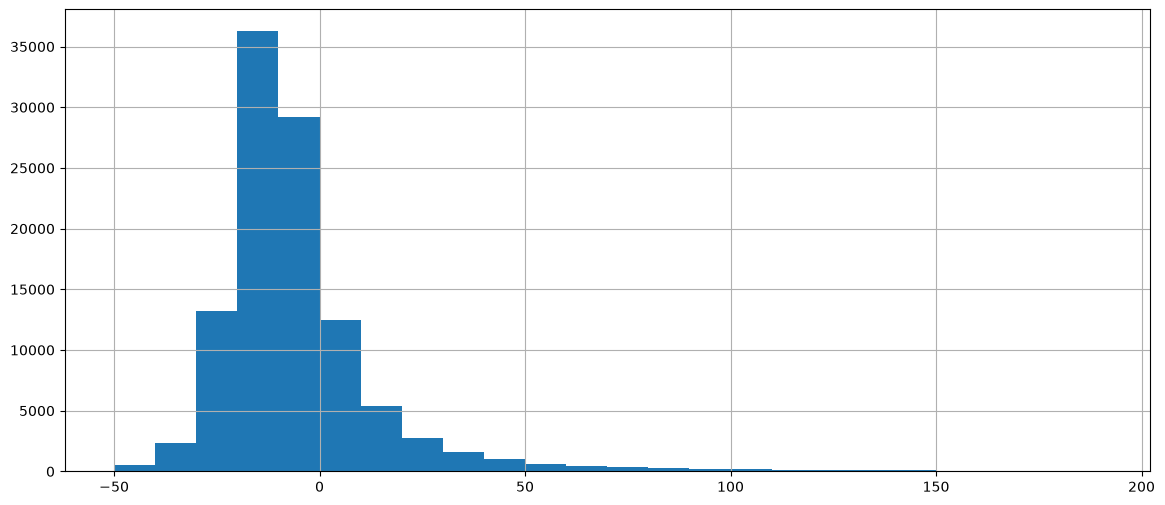

In [53]:
# histograms
bin_values = np.arange(start=-50, stop=200, step=10)
wn_carrier['arr_delay'].hist(bins=bin_values, figsize = [14, 6])

In [54]:
hi_volume = data['origin'].value_counts()[:20]
hi_volume.head()

origin
ATL    32190
ORD    25661
DFW    24339
DEN    20398
CLT    19995
Name: count, dtype: int64

In [55]:
hi_volume_airports_names = hi_volume.index.tolist()
hi_volume_airports_names

['ATL',
 'ORD',
 'DFW',
 'DEN',
 'CLT',
 'LAX',
 'PHX',
 'IAH',
 'LAS',
 'LGA',
 'SFO',
 'DTW',
 'MCO',
 'MSP',
 'BOS',
 'SEA',
 'DCA',
 'EWR',
 'JFK',
 'SLC']

## Part 1 Tasks

(1) Choose a dataset from the data repository of airlines delay. 

(2) Conduct EDA on the data. This includes descriptive statistics and data visualization as shown in the above cells. 

### Dataset: DelayedFlights.csv (2008, from the Kaggle airline delay causes dataset)

Note: this dataset only contains flights whose departure was delayed by more than 5 minutes, so every row is already a "delayed departure". We use `ArrDelay > 15` (the FAA definition of a late arrival) as our `delayed` flag.

In [56]:
flights = pd.read_csv('./data/DelayedFlights.csv', index_col=0)
print(flights.shape)
flights.head()

(1936758, 29)


,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,FlightNum,...,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2008,1,3,4,2003.0,1955,2211.0,2225,WN,335,...,4.0,8.0,0,N,0,NaN,NaN,NaN,NaN,NaN
1,2008,1,3,4,754.0,735,1002.0,1000,WN,3231,...,5.0,10.0,0,N,0,NaN,NaN,NaN,NaN,NaN
2,2008,1,3,4,628.0,620,804.0,750,WN,448,...,3.0,17.0,0,N,0,NaN,NaN,NaN,NaN,NaN
4,2008,1,3,4,1829.0,1755,1959.0,1925,WN,3920,...,3.0,10.0,0,N,0,2.0,0.0,0.0,0.0,32.0
5,2008,1,3,4,1940.0,1915,2121.0,2110,WN,378,...,4.0,10.0,0,N,0,NaN,NaN,NaN,NaN,NaN


In [57]:
# check data types and missing values
flights.info()
flights.isna().sum()

<class 'pandas.core.frame.DataFrame'>
Index: 1936758 entries, 0 to 7009727
Data columns (total 29 columns):
 #   Column             Dtype  
---  ------             -----  
 0   Year               int64  
 1   Month              int64  
 2   DayofMonth         int64  
 3   DayOfWeek          int64  
 4   DepTime            float64
 5   CRSDepTime         int64  
 6   ArrTime            float64
 7   CRSArrTime         int64  
 8   UniqueCarrier      object 
 9   FlightNum          int64  
 10  TailNum            object 
 11  ActualElapsedTime  float64
 12  CRSElapsedTime     float64
 13  AirTime            float64
 14  ArrDelay           float64
 15  DepDelay           float64
 16  Origin             object 
 17  Dest               object 
 18  Distance           int64  
 19  TaxiIn             float64
 20  TaxiOut            float64
 21  Cancelled          int64  
 22  CancellationCode   object 
 23  Diverted           int64  
 24  CarrierDelay       float64
 25  WeatherDelay       floa

Year                      0
Month                     0
DayofMonth                0
DayOfWeek                 0
DepTime                   0
CRSDepTime                0
ArrTime                7110
CRSArrTime                0
UniqueCarrier             0
FlightNum                 0
TailNum                   5
ActualElapsedTime      8387
CRSElapsedTime          198
AirTime                8387
ArrDelay               8387
DepDelay                  0
Origin                    0
Dest                      0
Distance                  0
TaxiIn                 7110
TaxiOut                 455
Cancelled                 0
CancellationCode          0
Diverted                  0
CarrierDelay         689270
WeatherDelay         689270
NASDelay             689270
SecurityDelay        689270
LateAircraftDelay    689270
dtype: int64

#### Preprocessing

- Drop cancelled / diverted flights (they have no arrival delay).
- Delay-cause columns are only filled in when the arrival delay is 15+ minutes, so missing values there mean 0 minutes.
- Add a `delayed` flag and a scheduled departure hour.

In [58]:
print('cancelled:', flights['Cancelled'].sum(), ' diverted:', flights['Diverted'].sum())
flights = flights[(flights['Cancelled'] == 0) & (flights['Diverted'] == 0)].copy()

cause_cols = ['CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay']
flights[cause_cols] = flights[cause_cols].fillna(0)

# FAA counts a flight as late if it arrives 15+ minutes behind schedule
flights['delayed'] = flights['ArrDelay'].apply(lambda x: x > 15)
flights['DepHour'] = (flights['CRSDepTime'] // 100).clip(0, 23)

print(flights.shape)
flights[['ArrDelay', 'DepDelay', 'Distance', 'TaxiOut', 'TaxiIn']].describe()

cancelled: 633  diverted: 7754
(1928371, 31)


,ArrDelay,DepDelay,Distance,TaxiOut,TaxiIn
count,1.928371e+06,1.928371e+06,1.928371e+06,1.928371e+06,1.928371e+06
mean,4.219988e+01,4.309169e+01,7.649486e+02,1.821733e+01,6.811388e+00
std,5.678472e+01,5.326600e+01,5.738858e+02,1.430838e+01,5.268051e+00
min,-1.090000e+02,6.000000e+00,1.100000e+01,0.000000e+00,0.000000e+00
25%,9.000000e+00,1.200000e+01,3.380000e+02,1.000000e+01,4.000000e+00
50%,2.400000e+01,2.400000e+01,6.060000e+02,1.400000e+01,6.000000e+00
75%,5.600000e+01,5.300000e+01,9.970000e+02,2.100000e+01,8.000000e+00
max,2.461000e+03,2.467000e+03,4.962000e+03,4.220000e+02,2.400000e+02


In [59]:
print('share arriving 15+ min late:', flights['delayed'].mean())

share arriving 15+ min late: 0.6300717030073569


<Axes: >

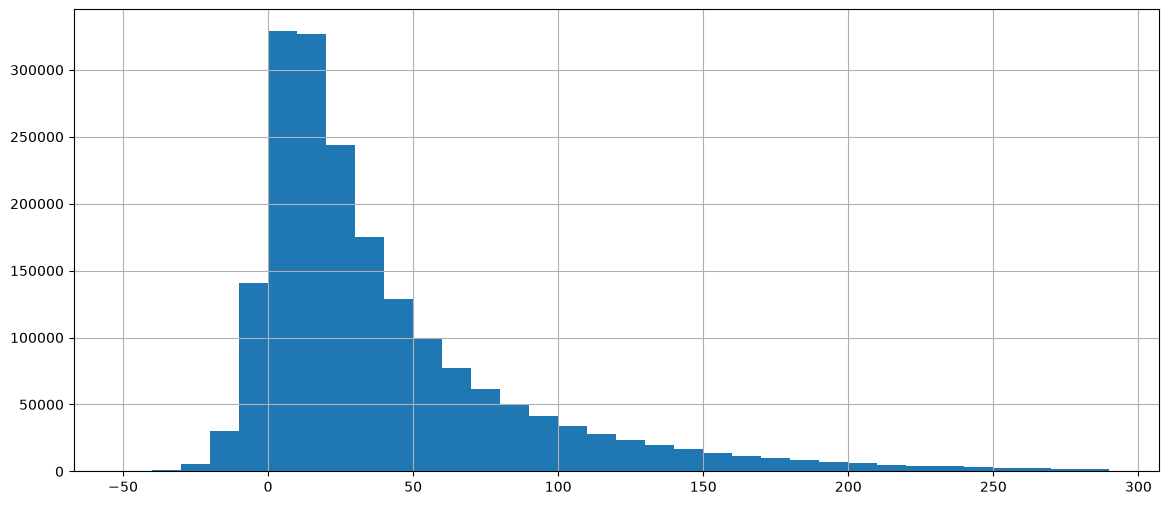

In [60]:
# histogram of arrival delays
bin_values = np.arange(start=-50, stop=300, step=10)
flights['ArrDelay'].hist(bins=bin_values, figsize=[14, 6])

In [61]:
# delay by carrier
delayed_by_carrier = flights.groupby('UniqueCarrier').agg(
    flight_count=('ArrDelay', 'size'),
    mean_arr_delay=('ArrDelay', 'mean'),
    median_arr_delay=('ArrDelay', 'median'),
    proportion_delayed=('delayed', 'mean'),
).sort_values('mean_arr_delay', ascending=False)
delayed_by_carrier

,flight_count,mean_arr_delay,median_arr_delay,proportion_delayed
UniqueCarrier,,,,
YV,66769,55.287049,34.0,0.741901
B6,54925,55.088739,33.0,0.683441
OH,52453,51.016968,33.0,0.731360
XE,103147,50.181217,30.0,0.683054
UA,140904,47.784399,29.0,0.662543
EV,81762,47.554255,28.0,0.678592
9E,51569,46.936493,28.0,0.675522
AA,190910,46.561553,29.0,0.677812
OO,131780,45.370587,27.0,0.657300


<Axes: ylabel='UniqueCarrier'>

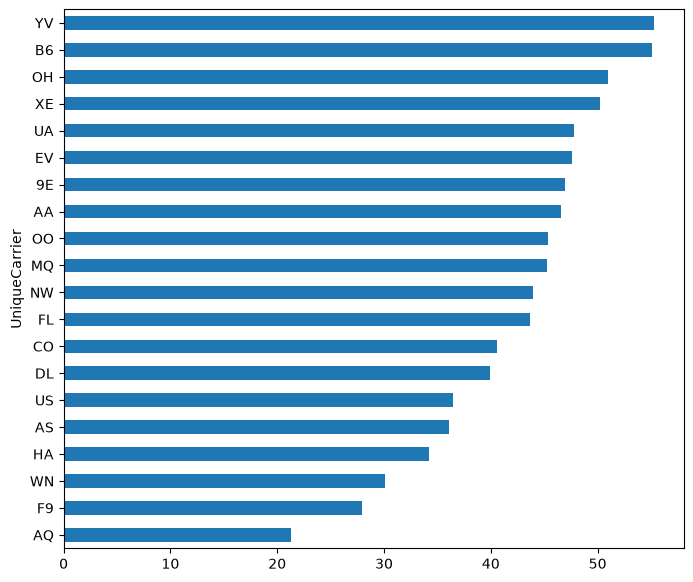

In [62]:
delayed_by_carrier['mean_arr_delay'].sort_values().plot(kind='barh', figsize=[8, 7])

<Axes: title={'center': 'ArrDelay'}, xlabel='UniqueCarrier'>

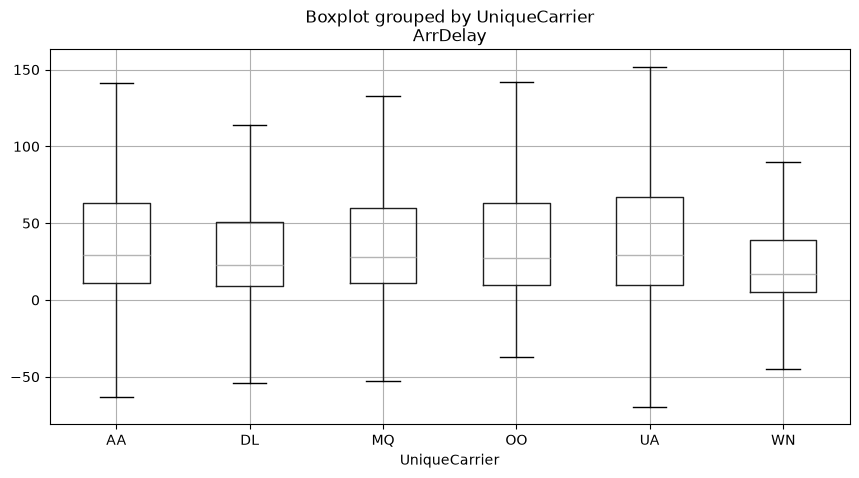

In [63]:
# box plot for the 6 busiest carriers (outliers hidden)
top_carriers = flights['UniqueCarrier'].value_counts()[:6].index.tolist()
flights[flights['UniqueCarrier'].isin(top_carriers)].boxplot(column='ArrDelay', by='UniqueCarrier', showfliers=False, figsize=[10, 5])

In [64]:
# share of total delay minutes by cause
cause_share = flights[cause_cols].sum() / flights[cause_cols].sum().sum()
cause_share.sort_values(ascending=False)

LateAircraftDelay    0.399684
CarrierDelay         0.303034
NASDelay             0.237342
WeatherDelay         0.058516
SecurityDelay        0.001424
dtype: float64

<Axes: >

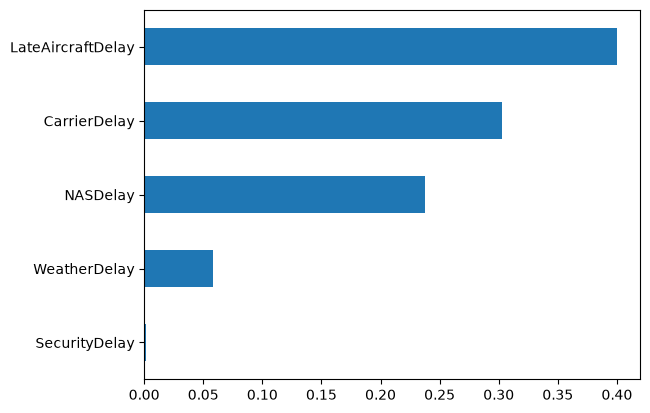

In [65]:
cause_share.sort_values().plot(kind='barh')

In [66]:
flights.groupby('Month').size()

Month
1     182915
2     188625
3     200116
4     154783
5     152711
6     199888
7     182171
8     161974
9      95351
10    103181
11    105148
12    201508
dtype: int64

<Axes: xlabel='Month'>

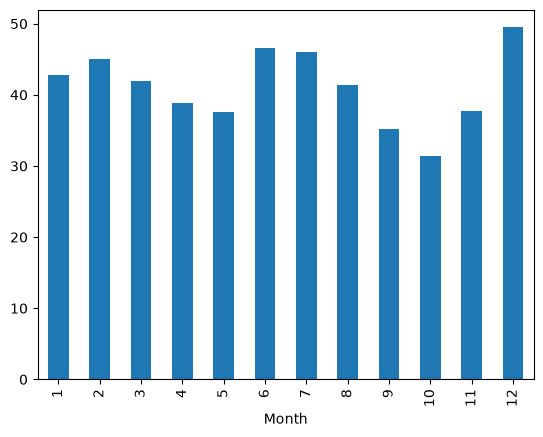

In [67]:
flights.groupby('Month')['ArrDelay'].mean().plot(kind='bar')

<Axes: xlabel='DayOfWeek'>

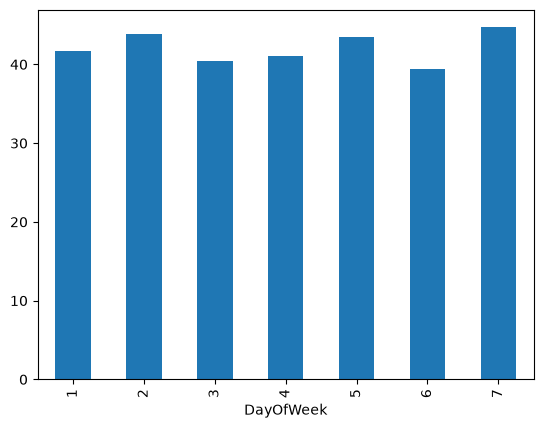

In [68]:
# 1 = Monday
flights.groupby('DayOfWeek')['ArrDelay'].mean().plot(kind='bar')

<Axes: xlabel='DepHour'>

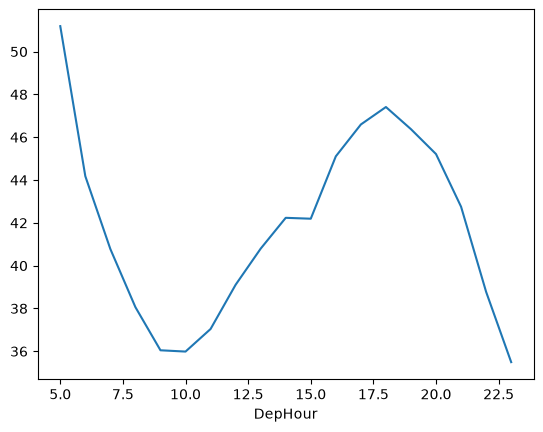

In [69]:
# hours 0-4 have very few flights, so start at 5am
flights[flights['DepHour'] >= 5].groupby('DepHour')['ArrDelay'].mean().plot()

In [70]:
# busiest 20 origin airports and their mean arrival delay
hi_volume_airports_names = flights['Origin'].value_counts()[:20].index.tolist()
hi_volume = flights[flights['Origin'].isin(hi_volume_airports_names)]

airport_delay = hi_volume.pivot_table(index='Origin', values='ArrDelay', aggfunc=['count', 'mean'])
airport_delay.columns = ['flight_count', 'mean_arr_delay']
airport_delay = airport_delay.sort_values('mean_arr_delay', ascending=False)
airport_delay

,flight_count,mean_arr_delay
Origin,,
JFK,34477,53.647301
LGA,31062,51.921190
ORD,125451,50.954747
EWR,52756,49.489366
PHL,30188,46.079601
SFO,43635,45.900493
DTW,43721,43.576496
MSP,32293,40.848574
CLT,34942,40.839591


<Axes: xlabel='Origin'>

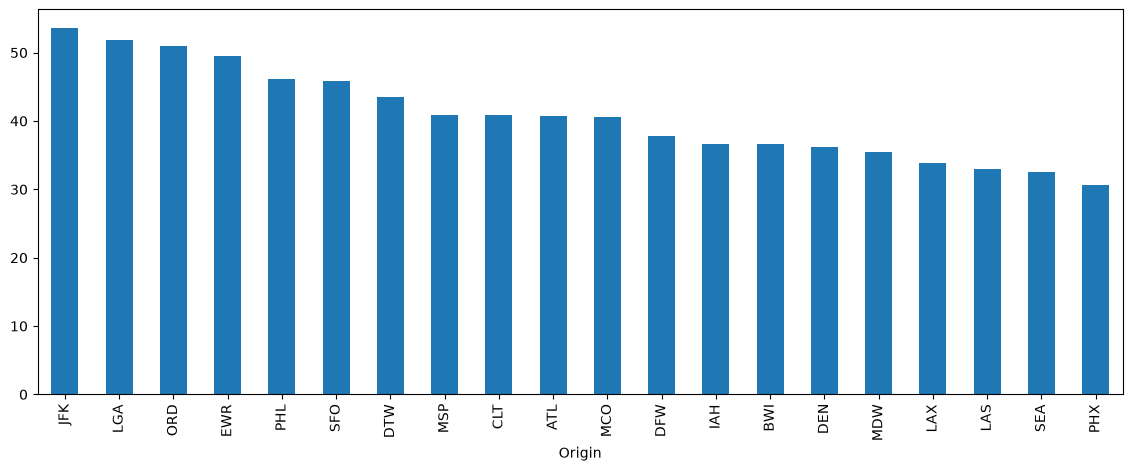

In [71]:
airport_delay['mean_arr_delay'].plot(kind='bar', figsize=[14, 5])

In [72]:
# correlation of arrival delay with other numeric columns
corr_cols = ['ArrDelay', 'DepDelay', 'Distance', 'TaxiOut', 'TaxiIn'] + cause_cols
flights[corr_cols].corr()['ArrDelay'].sort_values(ascending=False)

ArrDelay             1.000000
DepDelay             0.952927
LateAircraftDelay    0.556648
CarrierDelay         0.545013
NASDelay             0.450763
TaxiOut              0.286484
WeatherDelay         0.277743
TaxiIn               0.156277
SecurityDelay        0.011167
Distance            -0.029853
Name: ArrDelay, dtype: float64

<Axes: xlabel='DepDelay', ylabel='ArrDelay'>

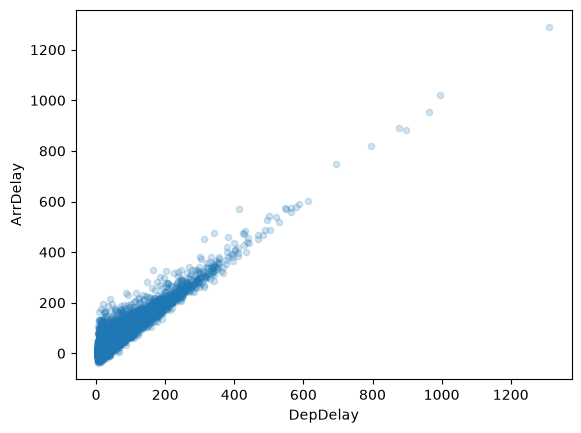

In [73]:
# scatter plots on a 20k sample (plotting ~2M points is slow)
sample = flights.sample(20000, random_state=0)
sample.plot.scatter(x='DepDelay', y='ArrDelay', alpha=0.2)

<Axes: xlabel='Distance', ylabel='ArrDelay'>

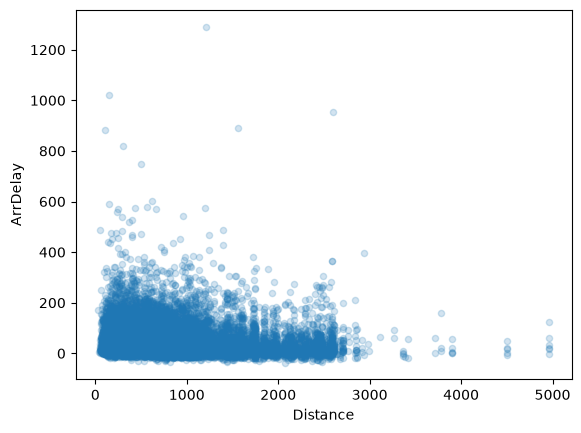

In [74]:
sample.plot.scatter(x='Distance', y='ArrDelay', alpha=0.2)

## Part 2

Write a summary of what you find from your data analysis. 

This dataset has about 1.9 million US domestic flights from 2008, (only includes flights that left 5+ min late).

In this dataset, the median arrival delay was 24 minutes, the average was about 42 minutes due to a small number of extreme delays, and about 63% arrived 15 or more minutes late. The biggest cause of lateness was late-arriving aircraft, at about 40% of total delay minutes, then airline problems at about 30%, and air traffic and congestion at about 24%. Weather only causd 6%. That suggests delays could cascade. with one late plane making its next few flights late as well. Departure delay and arrival delay were almost perfectly correlated, so planes rarely make up time in the air, and flight distance appeared to have no effect on delay.

Delays were also varied by airline, airport and timing. Regional and east coast carriers like JFK and ORD and were the worst, averaging >50min late. December and the summer months were the most delayed times to fly and the fall was the least delayed. Day of the week seemed largely irrelevant.

### Resources

#### Boxplot
https://towardsdatascience.com/understanding-boxplots-5e2df7bcbd51


- matplotlib.pyplot boxplot demo
https://matplotlib.org/3.1.1/gallery/pyplots/boxplot_demo_pyplot.html


#### matplotlib.pyplot
- scatter plot
https://matplotlib.org/3.3.2/api/_as_gen/matplotlib.pyplot.scatter.html


- histogram plot
https://matplotlib.org/3.3.2/api/_as_gen/matplotlib.pyplot.hist.html


#### pandas DataFrame
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.html


- describe()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.describe.html


- corr()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.corr.html


- hist()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.hist.html


- plot.scatter()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.plot.scatter.html


- pivot()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.pivot.html